In [1]:
from google.colab import drive
from google.colab import userdata

drive.mount('/content/drive')
drive_path = userdata.get('drive_path')

Mounted at /content/drive


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

### RFM Analysis

In [3]:
df = pd.read_csv(f'{drive_path}/rfm_data.csv')
df['last_visit_date'] = pd.to_datetime(df['last_visit_date'])

display(df.head())
display(df.info())
display(df.describe())


,account_id,visit_cnt,last_visit_date,revenue
0,671012,5,2020-11-22,50
1,681744,2,2020-12-29,20
2,671128,1,2020-12-14,10
3,671208,2,2021-02-09,20
4,671256,5,2021-01-22,50


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4463 entries, 0 to 4462
Data columns (total 4 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   account_id       4463 non-null   int64         
 1   visit_cnt        4463 non-null   int64         
 2   last_visit_date  4463 non-null   datetime64[ns]
 3   revenue          4463 non-null   int64         
dtypes: datetime64[ns](1), int64(3)
memory usage: 139.6 KB


None

,account_id,visit_cnt,last_visit_date,revenue
count,4463.000000,4463.000000,4463,4463.000000
mean,670989.628053,4.632982,2020-12-27 17:32:48.989468928,46.329823
min,657112.000000,1.000000,2020-11-01 00:00:00,10.000000
25%,666659.000000,1.000000,2020-12-07 00:00:00,10.000000
50%,671256.000000,3.000000,2020-12-27 00:00:00,30.000000
75%,675577.500000,6.000000,2021-01-18 00:00:00,60.000000
max,681956.000000,65.000000,2021-02-25 00:00:00,650.000000
std,5935.533819,5.795306,NaN,57.953061


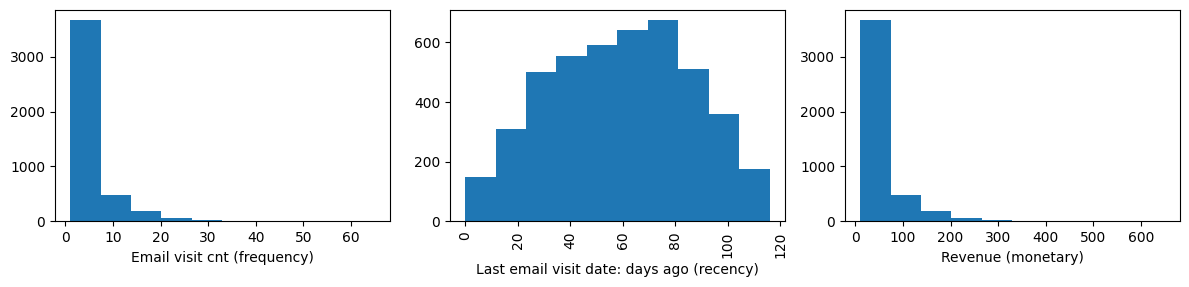

In [4]:
# revenue = visit_cnt × 10. Each email brings 10$ on average - this amount will be used for revenue calculation

analysis_date = np.max(df['last_visit_date'])

fix, ax = plt.subplots(1, 3, figsize=(12, 3))

ax[0].hist(x=df['visit_cnt'])
ax[0].set_xlabel('Email visit cnt (frequency)')

ax[1].hist(x=(analysis_date - df['last_visit_date']).dt.days)
ax[1].set_xlabel('Last email visit date: days ago (recency)')
ax[1].tick_params(axis='x', rotation=90)

ax[2].hist(x=df['revenue'])
ax[2].set_xlabel('Revenue (monetary)')


plt.tight_layout()
plt.show()

In [5]:
RFM_LEVELS = {
    'recency':   {'bins': [0, 30, 60, float('inf')], 'labels': ['A', 'B', 'C']},
    # 6 is the 75th percentile of visit_cnt, 3 is the median
    'frequency': {'bins': [0, 3, 6, float('inf')],   'labels': ['C', 'B', 'A']},
    'monetary':  {'bins': [0, 30, 60, float('inf')], 'labels': ['C', 'B', 'A']},
}
LETTER_TO_SCORE = {'A': 3, 'B': 2, 'C': 1}
SEGMENT_LEVELS = {'bins': [2, 4, 7, 9], 'labels': ['Lost', 'Middle', 'Top']}

def calc_rfm(df):
  df['recency'] = (analysis_date - df['last_visit_date']).dt.days
  df = df.drop('last_visit_date', axis=1)
  df.columns = ['account_id', 'frequency', 'monetary', 'recency']

  df['R'] = pd.cut(df['recency'], bins=RFM_LEVELS['recency']['bins'], include_lowest=True, labels=RFM_LEVELS['recency']['labels'])
  df['F'] = pd.cut(df['frequency'], bins=RFM_LEVELS['frequency']['bins'], labels=RFM_LEVELS['frequency']['labels'])
  df['M'] = pd.cut(df['monetary'], bins=RFM_LEVELS['monetary']['bins'], labels=RFM_LEVELS['monetary']['labels'])

  df['rfm_score'] = (df['R'].map(lambda value: LETTER_TO_SCORE[value])).astype(int) + (df['F'].map(lambda value: LETTER_TO_SCORE[value])).astype(int) + (df['M'].map(lambda value: LETTER_TO_SCORE[value])).astype(int)

  df['rfm_segment'] = pd.cut( df['rfm_score'], bins=SEGMENT_LEVELS['bins'], labels=SEGMENT_LEVELS['labels'])

  return df

rfm_df = df.copy()
result = calc_rfm(rfm_df)


In [6]:
# summary with percentages of accounts and revenue shares
summary = result.groupby('rfm_segment', observed=True).agg(
    accounts=('account_id', 'count'),
    revenue=('monetary', 'sum'),
    revenue_per_account=('monetary', 'mean'),
    avg_visits=('frequency', 'median'),
    median_recency=('recency', 'median')).reset_index()

summary['accounts_pct'] = summary['accounts'] / summary['accounts'].sum() * 100
summary['revenue_pct'] = summary['revenue'] / summary['revenue'].sum() * 100

### Results

In [7]:
print("-" * 50)
print("Accounts and Revenue Summary")
display(summary)

print("-" * 50)
print("RFM Metrcics Summary Statistics")
display(result[['recency', 'frequency', 'monetary']].describe())

print("-" * 50)
print("RFM Sample Results")
display(result.head(5))


--------------------------------------------------
Accounts and Revenue Summary


,rfm_segment,accounts,revenue,revenue_per_account,avg_visits,median_recency,accounts_pct,revenue_pct
0,Lost,2335,38510,16.492505,1.0,69.0,52.319068,18.624559
1,Middle,1576,93520,59.340102,5.0,60.0,35.312570,45.228998
2,Top,552,74740,135.398551,11.0,35.0,12.368362,36.146443


--------------------------------------------------
RFM Metrcics Summary Statistics


,recency,frequency,monetary
count,4463.000000,4463.000000,4463.000000
mean,59.268877,4.632982,46.329823
std,26.749646,5.795306,57.953061
min,0.000000,1.000000,10.000000
25%,38.000000,1.000000,10.000000
50%,60.000000,3.000000,30.000000
75%,80.000000,6.000000,60.000000
max,116.000000,65.000000,650.000000


--------------------------------------------------
RFM Sample Results


,account_id,frequency,monetary,recency,R,F,M,rfm_score,rfm_segment
0,671012,5,50,95,C,B,B,5,Middle
1,681744,2,20,58,B,C,C,4,Lost
2,671128,1,10,73,C,C,C,3,Lost
3,671208,2,20,16,A,C,C,5,Middle
4,671256,5,50,34,B,B,B,6,Middle


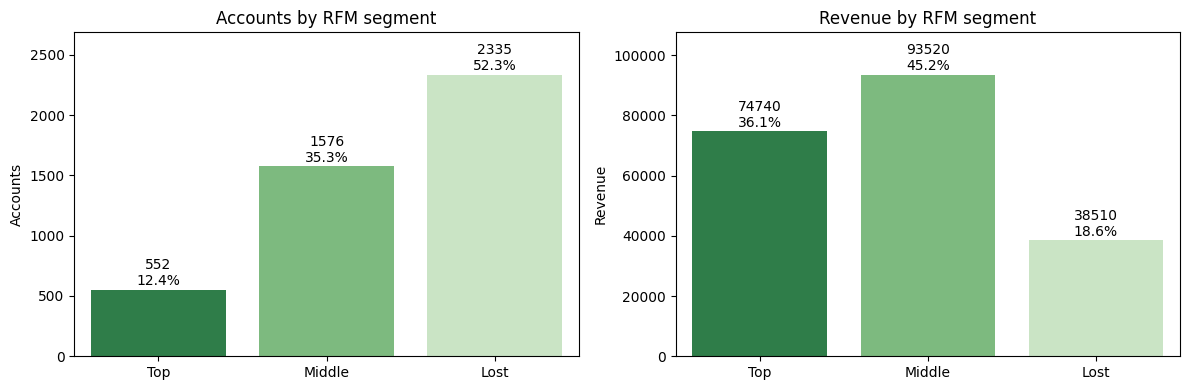

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

sns.countplot(data=result, x='rfm_segment', order=['Top', 'Middle', 'Lost'],
              palette='Greens', hue='rfm_segment', legend=False, ax=ax[0])

n=len(result)
for c in ax[0].containers:
    ax[0].bar_label(c,
                    labels=[f'{int(v)}\n{v / n:.1%}' for v in c.datavalues],
                    padding=1)

ax[0].set_title('Accounts by RFM segment')
ax[0].set_xlabel('')
ax[0].set_ylabel('Accounts')
ax[0].margins(y=0.15)

revenue_sum = sum(summary['revenue'])
sns.barplot(x=summary['rfm_segment'], y=summary['revenue'], order=['Top', 'Middle', 'Lost'], palette='Greens', hue=summary['rfm_segment'], legend=False, ax=ax[1])
for c in ax[1].containers:
    ax[1].bar_label(c,
                    labels=[f'{int(v)}\n{v / revenue_sum:.1%}' for v in c.datavalues],
                    padding=1)
ax[1].set_title('Revenue by RFM segment')
ax[1].set_xlabel('')
ax[1].set_ylabel('Revenue')
ax[1].margins(y=0.15)


plt.tight_layout()
plt.show()

### Conclusions

#### Data

4,463 accounts that opened at least one email between 2020-11-01
and 2021-02-25.

#### Method

Each account scored 1–3 on recency, frequency and monetary. Scores sum to 3-9: Top 8–9, Middle 5–7, Lost 3–4.

#### The main finding

- On average **Top account brings \$135** - **8 times more than a Lost one** \$16 on average. Top users are more valuable.

- **Half** the base (Lost) generates **less than 20% of the revenue**.

- **A third of the base (Middle) brings 45% of revenue** — slightly less than Top and Lost combined.

#### Recommendation
**Top – protect.** Maintain loyalty: special personalized offerings, loyalty programs.

**Middle – protect & grow.** Pull up to Top tier: personalized offerings, promotions, product recommendations.

**Lost – try to return or stop.** Try running a win-back campaign. If that does not work – stop investing.





